In [49]:
import numpy as np
# import tabix
import sys
import os
import json
# import h5py
from subprocess import Popen, PIPE

import scipy.stats as stats
# from simsearch_functions import simsearch, roiURL  # , load_per

import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error


def top_region_sig(percents, top_regions):
    # mean and std of factor percentiles in all regions
    all_mean = np.mean(percents, axis=0)
    all_std = np.std(percents, axis=0)

    # mean of factor percentiles in most similar regions
    top_region_mean = np.mean(percents[top_regions[:, 1:]], axis=1)

    # Z score
    Z = (top_region_mean - all_mean) / (all_std / np.sqrt(top_regions.shape[1] - 1))

    # p-value (one sided)
    pval = stats.norm.sf(Z)

    return pval, Z

def factor_sum_ranks(roi_percents, percents, target_factors, top_regions):
    # init array
    sum_ranks = np.zeros(top_regions.shape)
    # rank values for each of the similar regions at each detail level
    sim_percents = percents[top_regions[:, 1:]]

    for dl in range(1, len(target_factors) + 1):
        # fusion of factor ranks for query at detail level
        query_sum = np.sum(roi_percents[target_factors[:dl]])
        # fusion of factor ranks for similar regions at detail level
        sim_sum = np.sum(sim_percents[dl-1][:, target_factors[:dl]], axis=1)
        # fusion of factor ranks for search space at detail level
        search_space_sum = np.sum(percents[:, target_factors[:dl]], axis=1)

        # rank query
        query_sum_rank = stats.percentileofscore(search_space_sum, query_sum, kind='strict')
        # rank similar regions
        sim_sum_ranks = stats.percentileofscore(search_space_sum, sim_sum, kind='strict')

        # add ranks to array
        sum_ranks[dl - 1][0] = query_sum_rank
        sum_ranks[dl - 1][1:] = sim_sum_ranks
    return sum_ranks

def simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions):

    # factors the query region ranks highest in
    query_factor_order = np.argsort(-roi_percents)

    # factors to search over
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ]

    # convolution
    roi_percents_targeted = roi_percents[target_factors]
    # normal convolution
    # roi_conv_all = percents[:, target_factors] * roi_percents_targeted
    # penalized convolution
    roi_conv_all = ((percents[:, target_factors] * 2) - 1) * ((roi_percents_targeted * 2) - 1)

    # fusion
    roi_sim_all = []
    for dl in range(1, len(included_factors) + 1):
        roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
        roi_sim_all.append(roi_sim)
    roi_sim_all = np.array(roi_sim_all)

    # most similar regions
    top_regions = np.zeros(
        (len(included_factors), num_similar_regions + 1)
        , dtype=int
    )

    # top region genomic coordinates
    top_region_coords = np.ones(
        (len(included_factors), num_similar_regions + 1, 3),
        dtype=object
    ) * -1

    # add roi to top region lists
    top_regions[:, 0] = roi
    top_region_coords[:, 0] = roi_coords
    
    # adding similar regions
    sorted_sim_inds_all = np.argsort(-roi_sim_all, axis=1)

    # only add regions if no overlapping regions are already added
    for i in range(len(target_factors)):
        regions_added = 0
        for ind in sorted_sim_inds_all[i]:
            ind_coords = coords[ind]
            num_overlaps = np.count_nonzero(
                (top_region_coords[i][:, 0].astype(str) == ind_coords[0]) &
                (
                    (
                        (top_region_coords[i][:, 1].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 1].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 2].astype(int) > int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) < int(ind_coords[2]))
                    ) |
                    (
                        (top_region_coords[i][:, 1].astype(int) == int(ind_coords[1])) &
                        (top_region_coords[i][:, 2].astype(int) == int(ind_coords[2]))
                    )
                )
            )
            if num_overlaps == 0:
                top_regions[i, regions_added + 1] = ind
                top_region_coords[i, regions_added + 1] = ind_coords
                regions_added += 1
            if regions_added == num_similar_regions:
                break

    # rank of query factor products for each detail level
    # query_sim_prod_ranks = factor_prod_ranks(roi_percents, percents, target_factors, top_regions)
    # query_sim_prod_ranks = factor_fusion_ranks(roi_percents, percents, target_factors, top_regions)
    query_sim_prod_ranks = factor_sum_ranks(roi_percents, percents, target_factors, top_regions)

    # factor percentile significance
    pval, Z = top_region_sig(percents, top_regions)

    rows = (
        np.ones((len(target_factors), num_similar_regions), dtype=int) *
        np.arange(len(target_factors)).reshape(-1, 1)
    )

    return_sim = np.hstack((
        np.ones(len(target_factors)).reshape(-1, 1),
        roi_sim_all[rows, top_regions[:, 1:]]
    ))
    return_per = np.hstack((
        np.array([roi_percents.reshape(1, -1)] * len(target_factors)),
        percents[top_regions[:, 1:]]
    ))

    return (top_regions, top_region_coords, return_sim, return_per,
            query_factor_order, target_factors, pval, Z, query_sim_prod_ranks)











data_dir = '/home/ctrader/region_similarity/data/rank_based/'

# Given a scale, build a path name for the search space
def build_search_space_path(scale):
    path = os.path.join(data_dir, 'regions_{}kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'.format(scale))
    return path


"""
# Given a scale, build a path name for the query region
def build_query_path(scale):
    path = os.path.join(data_dir, 'regions_{}kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(scale))
    return path
"""



# Given a scale, build a path name for the tabix query
def build_tabix_path(scale):
    # path = os.path.join(data_dir, 'hg38.{}kb.regions.CT20230412.sorted.rownum4.bed.gz'.format(scale))
    path = 'https://resources.altius.org/~ctrader/public/genomic_narration/indexed/hg38.{}kb.regions.CT20230427.sorted.rownum4.factorranks5t38.bed.gz'.format(scale)
    return path


# Load search space data from a given scale
def load_ranks(search_space_path):
    search_space = np.load(search_space_path)
    percents = search_space['percentiles']
    coords = search_space['coordinates']
    return percents, coords


# load search spaces for all scales into dict
seach_spaces = {}
for scale in [1, 2, 5, 10, 15, 25, 50, 75, 100]:
    seach_spaces[scale] = load_ranks(build_search_space_path(scale))


# Functions for narration

def tabix_query(filename, query):
    # Use subprocess with tabix and return hits
    process = Popen(['tabix', '-f', filename, query], stdout=PIPE)

    hits = []
    for line in process.stdout:
        hits.append(np.char.decode(line.strip().split()))
    hits = np.array(hits)
    return hits




# determine roi from query coordinates
def load_roi(genomic_location, link_path):
    global roi, roi_percents, roi_coords

    # determine chromosome, start, and end from query
    query_start_end = genomic_location.split(':')[1].split('-')
    query_start = int(query_start_end[0])
    query_end = int(query_start_end[1])

    # retrieve possible rois
    possible_coords = tabix_query(link_path, genomic_location)

    # find closest roi
    start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
    end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)
    query_region = possible_coords[np.argmin(start_dist + end_dist)]

    roi = int(query_region[3])
    roi_percents = query_region[4:].astype('float32')
    roi_coords = query_region[:3]

    return


# choose search space from scale options
def choose_search_space(scale):
    global percents, coords

    percents, coords = seach_spaces[scale]


# find the factors we want to search over
def setup_included_factors(included_factors_str, query_factor_thresh):
    global included_factors

    included_factors_from_str = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )
    query_factors_above_thresh = np.where(roi_percents > query_factor_thresh)[0]

    # if no factors above threshold, search best one
    if len(query_factors_above_thresh) == 0:
        sort_order = np.argsort(-roi_percents)
        included_factors = sort_order[
            np.isin(sort_order, included_factors_from_str)
        ][:1]
    else:
        included_factors = included_factors_from_str[
            np.isin(included_factors_from_str, query_factors_above_thresh)
        ]
    # included_factors=np.arange(34)

# given our roi, find the similar regions
def find_most_similar_region_indices(num_similar_regions):
    global top_regions, top_region_coords, top_regions_sim, top_regions_per, query_factor_order, target_factors, pval, Z, query_sim_prod_ranks
    (top_regions, top_region_coords, top_regions_sim,
     top_regions_per, query_factor_order,
     target_factors, pval,
     Z, query_sim_prod_ranks) = simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions)



    
# generate roiURL to view similar regions in index browser
def setup_roiURLs(get_roiURL, target_factors):
    global roiURLs
    roiURLs = []
    for dl in range(1, len(included_factors) + 1):
        if get_roiURL == 'Tru':  # 'True'
            # roiURLs.append('roiURL not available')
            roiURLs.append(roiURL(roi, top_region_coords[dl-1],
                                  dl, '_'.join(target_factors.astype(str))))
        else:
            roiURLs.append('roiURL not available')


# reorder data based on ranks in query region/roi
def reorder_by_query_region():
    global return_top_regions_per, return_pval, return_Z
    return_top_regions_per = top_regions_per[:, :, query_factor_order]
    return_pval = pval[:, query_factor_order]
    return_Z = Z[:, query_factor_order]
    
    
# build array of objects for roi and each similar region at each detail level
def generate_result_array(num_similar_regions):
    global return_arr_full
    return_arr_full = []
    for dl in range(len(included_factors)):
        # for the roi, return results as json array
        # each element is an object of scores for each metric
        return_arr = []
        for rank in range(num_similar_regions + 1):
            coord = top_region_coords[dl, rank]
            region_dict = {
                'rank': rank,
                'coordinates': coord[0] + ':' + coord[1] + '-' + coord[2],
                'region_ind': int(top_regions[dl, rank]),
                'score': float(top_regions_sim[dl, rank]),
                'percentiles': return_top_regions_per[dl, rank].tolist(),
                'prod_rank': query_sim_prod_ranks[dl, rank]
            }
            if rank == 0:
                region_dict['region_ind'] = 'NA'
                region_dict['score'] = 'NA'
                region_dict['query_factor_order'] = query_factor_order.tolist()
                region_dict['target_factors'] = target_factors.tolist()
                region_dict['top_region_factor_Z_score'] = return_Z[dl].tolist()
                region_dict['top_region_factor_pval'] = return_pval[dl].tolist()
                region_dict['roiURL'] = roiURLs[dl]
                region_dict['detail_level'] = dl + 1
                # region_dict['query_prod_rank'] = query_sim_prod_ranks[dl]
            return_arr.append(region_dict)

        return_arr_full.append(return_arr)
        
        


In [140]:
genomic_location = 'chr1:1107000-1117000'
gene = 'HAND2'
scale = 10
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) + ']'
get_roiURL = 'False'
query_factor_thresh = 0.5
num_similar_regions = 20

# get roi
load_roi(genomic_location, build_tabix_path(scale))

# choose search space
choose_search_space(scale)

# factors the user cares about
setup_included_factors(included_factors_str, query_factor_thresh)

# find most similar region inds
find_most_similar_region_indices(num_similar_regions)

# dual track roiURL
setup_roiURLs(get_roiURL, target_factors)

# reorder based on query region
reorder_by_query_region()

# generate result array
generate_result_array(num_similar_regions)

In [141]:
mse = []
mse_all = []
for dl in range(return_top_regions_per.shape[0]):
    query = return_top_regions_per[dl, 0, :dl+1]
    hits = return_top_regions_per[dl, 1:, :dl+1]
    hits_mean = np.mean(hits, axis=0)
    
    query_all = return_top_regions_per[dl, 0, :]
    hits_all = return_top_regions_per[dl, 1:, :]
    hits_all_mean = np.mean(hits_all, axis=0)
    
    mse.append(mean_squared_error(query, hits_mean))
    mse_all.append(mean_squared_error(query_all, hits_all_mean))

Text(0.5, 1.0, 'chr1:1107000-1117000, Scale: 10kb')

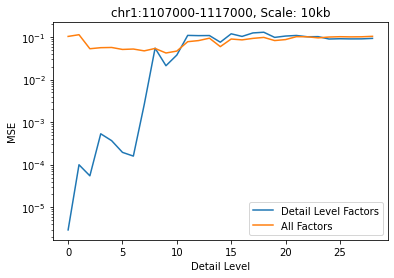

In [142]:
plt.plot(np.arange(len(mse)), mse)
plt.plot(np.arange(len(mse_all)), mse_all)
plt.yscale('log')
plt.xlabel('Detail Level')
plt.ylabel('MSE')
plt.legend(['Detail Level Factors', 'All Factors'])
plt.title(genomic_location + ', Scale: ' + str(scale) + 'kb')#, Gene: ' + gene)